# Anemia severity classification — 3 classes
Adapted pipeline for **Normal (0), Leve/Mild (1), Moderada/Moderate (2)**.
This is multiclass classification, not Anemic vs Non-anemic. Run cells top-to-bottom.
Important: class labels must genuinely identify severity. Generic labels such as only “anemia” are not enough to distinguish Leve from Moderada. If using Hb values, the thresholds below are configurable and severe cases are excluded unless you define a clinically approved policy.


In [49]:
# CELL 1 - setup, paths, config
import os, re, json, glob, random, warnings, time, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings("ignore")

MANUAL_PATHS = {
    "csv": "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",
    "metadata": "/kaggle/input/datasets/shimu080/metadata/metadata.csv",
    "yemas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",
    "palmas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",
    "unas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",
}
SITES = ["palmas", "unas", "yemas"]      # palm, fingernail, fingertip-pad

CFG = dict(
    SEED=42, IMG_SIZE=128,
    HB_NORMAL_MIN=11.0,           # configurable Hb cutoff (g/dL); verify against study criteria
    HB_MILD_MIN=10.0,             # Hb in [10, 11) -> Leve/Mild
    HB_MODERATE_MIN=7.0,          # Hb in [7, 10) -> Moderada; below 7 treated as severe/unmapped
    CLASS_NAMES=["Normal", "Leve", "Moderada"],
    NUM_CLASSES=3,
    TEST_FRAC=0.15, VAL_FRAC=0.15,  # paper: 70/10/20
    KNN_K=5,                      # paper text says 100 neighbours / k=2 (inconsistent) -> change if you want
    USE_EXTRA_FEATS=True,         # paper uses a*, b*, G ; extras = L, R, B, a_std
    CNN_EPOCHS=30, CNN_BATCH=32, CNN_LR=0.01,
    FORCE_RERUN=True,            # True = ignore checkpoints
)
WORK = Path("/kaggle/working/anemia_ckpt_3class")
for d in ["features", "splits", "results", "cnn", "models"]:
    (WORK / d).mkdir(parents=True, exist_ok=True)
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"])
print("checkpoint dir:", WORK)

checkpoint dir: /kaggle/working/anemia_ckpt_3class


In [42]:
# CELL 2 - explore the data (look at this output before going on)
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT)

for k in ["csv", "metadata"]:
    df_ = pd.read_csv(MANUAL_PATHS[k])
    print(f"\n===== {k}: shape={df_.shape}")
    print(list(df_.columns))
    display(df_.head())

for s in SITES:
    imgs = list_images(MANUAL_PATHS[s])
    print(f"\n===== {s}: {len(imgs)} images")
    root = Path(MANUAL_PATHS[s])
    for p in imgs[:5]:
        print("  ", p.relative_to(root))
    subdirs = sorted({str(p.parent.relative_to(root)) for p in imgs})
    print("   subfolders:", subdirs[:10], "..." if len(subdirs) > 10 else "")


===== csv: shape=(999, 7)
['ID', 'Class', 'Anemia Predict', 'Split', 'YEMAS Path', 'PALMAS Path', 'UNAS Path']


,ID,Class,Anemia Predict,Split,YEMAS Path,PALMAS Path,UNAS Path
0,ID001,Normal,0,train,dataset/yemas/Normal/20230706_211043.mp4,dataset/palmas/Normal/20230706_211218.mp4,dataset/unas/Normal/20230706_211246.jpg
1,ID002,Normal,0,train,NaN,NaN,NaN
2,ID003,Normal,0,train,dataset/yemas/Normal/20230706_205929.mp4,dataset/palmas/Normal/20230706_210050.mp4,dataset/unas/Normal/20230706_210140.jpg
3,ID004,Leve,1,train,dataset/yemas/Leve/20230706_205753.mp4,dataset/palmas/Leve/20230706_205901.mp4,dataset/unas/Leve/20230706_205941.jpg
4,ID005,Moderada,1,validation,dataset/yemas/Moderada/20230706_205551.mp4,dataset/palmas/Moderada/20230706_205659.mp4,dataset/unas/Moderada/20230706_205732.jpg



===== metadata: shape=(909, 22)
['ID', 'Sexo', 'Edad', 'Fatiga', 'Debilidad', 'Latidos irregulares', 'Dificultad para respirar', 'Mareos o aturdimiento', 'Dolor en el pecho', 'Manos y pies fríos', 'Dolores de cabeza', 'Normal', 'Leve', 'Moderado', 'Frecuencia Cardiaca', 'Hemoglobina', 'Oxígeno', 'Peso', 'Talla', 'YEMAS', 'PALMAS', 'UNAS']


,ID,Sexo,Edad,Fatiga,Debilidad,Latidos irregulares,Dificultad para respirar,Mareos o aturdimiento,Dolor en el pecho,Manos y pies fríos,...,Leve,Moderado,Frecuencia Cardiaca,Hemoglobina,Oxígeno,Peso,Talla,YEMAS,PALMAS,UNAS
0,ID001,M,25,0,0,1,0,0,0,0,...,0,0,70.0,13.6,98,89.0,183.0,20230706_211043.mp4,20230706_211218.mp4,20230706_211246.jpg
1,ID002,M,25,1,1,0,0,0,0,0,...,0,0,77.0,13.7,98,76.0,165.0,NaN,NaN,NaN
2,ID003,M,23,0,0,0,0,1,0,0,...,0,0,66.0,14.3,98,64.8,159.0,20230706_205929.mp4,20230706_210050.mp4,20230706_210140.jpg
3,ID004,F,23,1,1,0,1,1,1,1,...,1,0,85.0,11.5,99,70.2,159.0,20230706_205753.mp4,20230706_205901.mp4,20230706_205941.jpg
4,ID005,F,24,0,0,0,0,0,0,0,...,0,1,75.0,10.8,98,64.1,152.0,20230706_205551.mp4,20230706_205659.mp4,20230706_205732.jpg



===== palmas: 13328 images
   Leve/ID004/frame_000.jpg
   Leve/ID004/frame_001.jpg
   Leve/ID004/frame_002.jpg
   Leve/ID004/frame_003.jpg
   Leve/ID004/frame_004.jpg
   subfolders: ['Leve/ID004', 'Leve/ID015', 'Leve/ID018', 'Leve/ID019', 'Leve/ID020', 'Leve/ID021', 'Leve/ID022', 'Leve/ID024', 'Leve/ID026', 'Leve/ID028'] ...

===== unas: 826 images
   Leve/ID004.jpg
   Leve/ID015.jpg
   Leve/ID018.jpg
   Leve/ID019.jpg
   Leve/ID020.jpg
   subfolders: ['Leve', 'Moderada', 'Normal'] 

===== yemas: 26816 images
   Leve/ID004/frame_000.jpg
   Leve/ID004/frame_001.jpg
   Leve/ID004/frame_002.jpg
   Leve/ID004/frame_003.jpg
   Leve/ID004/frame_004.jpg
   subfolders: ['Leve/ID004', 'Leve/ID015', 'Leve/ID018', 'Leve/ID019', 'Leve/ID020', 'Leve/ID021', 'Leve/ID022', 'Leve/ID024', 'Leve/ID026', 'Leve/ID028'] ...


In [43]:

# CELL 3 - build image index with 3-class severity labels (+ patient ids)

CSV_ID_COL = None
CSV_LABEL_COL = None
PATIENT_ID_FN = None

CLASS_TO_ID = {
    "normal": 0, "healthy": 0, "sano": 0, "control": 0,
    "leve": 1, "mild": 1, "mild anemia": 1, "mild anaemia": 1,
    "anemia leve": 1, "anaemia leve": 1, "leve anemia": 1, "leve anaemia": 1,
    "moderada": 2, "moderate": 2, "moderate anemia": 2, "moderate anaemia": 2,
    "anemia moderada": 2, "anaemia moderada": 2,
    "moderada anemia": 2, "moderada anaemia": 2,
}

def label_from_text(s):
    t = re.sub(r"[_\-]+", " ", str(s).strip().lower())
    t = re.sub(r"\s+", " ", t)

    if re.search(r"\b(moderada|moderate)\b", t):
        return 2
    if re.search(r"\b(leve|mild)\b", t):
        return 1
    if re.search(r"\b(normal|healthy|sano|control)\b", t):
        return 0

    return CLASS_TO_ID.get(t)


def default_pid(stem):
    pid = re.sub(
        r"[_\-\s]*(frame|fr)[_\-\s]*\d+$",
        "",
        str(stem),
        flags=re.I
    ).strip("_- ")
    return pid if pid else str(stem)


rows = []

for site in SITES:
    root = Path(MANUAL_PATHS[site])

    for p in list_images(root):
        rel = str(p.relative_to(root))

        # Extract ID from folder, e.g. Leve/ID004/frame_000.jpg
        parts = Path(rel).parts

        pid = next(
            (
                part for part in parts
                if re.fullmatch(r"ID\d+(?:_\d+)?", part, flags=re.I)
            ),
            None
        )

        # For nail images, e.g. Leve/ID004.jpg
        if pid is None:
            candidate = Path(rel).stem
            if re.fullmatch(r"ID\d+(?:_\d+)?", candidate, flags=re.I):
                pid = candidate

        if pid is None:
            raise ValueError(f"Participant ID not found: {rel}")

        pid = pid.upper()

        rows.append({
            "site": site,
            "path": str(p),
            "rel": rel,
            "stem": p.stem,
            "patient": str(pid),
            "label": label_from_text(rel)
        })


idx = pd.DataFrame(rows)

cov_names = idx.label.notna().mean()
print(f"3-class labels found from folder/file names: {cov_names:.1%}")


def pick_col(df, keys):
    for c in df.columns:
        if any(k in c.lower() for k in keys):
            return c
    return None


def to_label(v, hb_mode):
    if pd.isna(v):
        return None

    if hb_mode:
        try:
            hb = float(v)
            if hb >= CFG["HB_NORMAL_MIN"]:
                return 0
            if CFG["HB_MILD_MIN"] <= hb < CFG["HB_NORMAL_MIN"]:
                return 1
            if CFG["HB_MODERATE_MIN"] <= hb < CFG["HB_MILD_MIN"]:
                return 2
            return None
        except (TypeError, ValueError):
            return None

    if isinstance(v, (int, float, np.integer, np.floating)):
        iv = int(v)
        return iv if float(v) == iv and iv in (0, 1, 2) else None

    t = re.sub(r"[_\-]+", " ", str(v).strip().lower())
    t = re.sub(r"\s+", " ", t)

    if t in {"0", "1", "2"}:
        return int(t)

    return label_from_text(t)


if cov_names < 0.9:
    best = (0, None, None)

    for src_name in ["csv", "metadata"]:
        src = pd.read_csv(MANUAL_PATHS[src_name])

        id_col = (
            CSV_ID_COL
            if CSV_ID_COL is not None and CSV_ID_COL in src.columns
            else pick_col(src, ["id", "name", "file", "image", "patient", "sample"])
        )

        lab_col = (
            CSV_LABEL_COL
            if CSV_LABEL_COL is not None and CSV_LABEL_COL in src.columns
            else pick_col(src, ["severity", "anem", "label", "class", "hb", "hemo"])
        )

        if id_col is None or lab_col is None:
            print(f"[{src_name}] Could not guess columns; check CSV_ID_COL / CSV_LABEL_COL")
            continue

        hb_mode = pd.api.types.is_numeric_dtype(src[lab_col]) and (
            any(k in lab_col.lower() for k in ["hb", "hemo"])
            or (
                not src[lab_col].dropna().empty
                and src[lab_col].dropna().max() > 2.5
            )
        )

        mp = {}

        for i_, v_ in zip(src[id_col], src[lab_col]):
            lab = to_label(v_, hb_mode)

            if lab is not None:
                key = str(i_).strip().lower()
                mp[key] = lab
                mp[Path(key).stem] = lab

        lab_series = [
            mp.get(str(r.patient).lower(), mp.get(str(r.stem).lower()))
            for r in idx.itertuples()
        ]

        cov = pd.Series(lab_series).notna().mean()

        print(
            f"[{src_name}] id_col={id_col!r} "
            f"label_col={lab_col!r} hb_mode={hb_mode} "
            f"-> matched 3-class labels {cov:.1%}"
        )

        if cov > best[0]:
            best = (cov, src_name, lab_series)

    if best[1] is not None and best[0] > cov_names:
        idx["label"] = best[2]
        print("Using labels from", best[1])


n0 = len(idx)
idx = idx[idx.label.notna()].copy()
idx["label"] = idx["label"].astype(int)

if not set(idx.label.unique()).issubset({0, 1, 2}):
    raise RuntimeError("Unexpected labels: expected 0=Normal, 1=Leve, 2=Moderada.")

print(f"Images with usable 3-class labels: {len(idx)}/{n0}")
print(
    "Class counts:",
    idx.label.map({0: "Normal", 1: "Leve", 2: "Moderada"})
       .value_counts().to_dict()
)

missing = set([0, 1, 2]) - set(idx.label.unique())

if missing:
    raise RuntimeError(
        f"Missing class(es) {missing}. Check dataset label names/CSV mapping; "
        "do not continue with fewer than 3 classes."
    )

if len(idx) < 0.5 * n0:
    raise RuntimeError(
        "Less than 50% of images got 3-class labels. "
        "Check CSV_ID_COL, CSV_LABEL_COL, and patient IDs."
    )

print(idx.groupby(["site", "label"]).size().unstack(fill_value=0))
print("Unique patients:", idx.patient.nunique())

display(idx.head())


3-class labels found from folder/file names: 100.0%
Images with usable 3-class labels: 40970/40970
Class counts: {'Normal': 27367, 'Leve': 9946, 'Moderada': 3657}
label       0     1     2
site                     
palmas   8896  3248  1184
unas      551   202    73
yemas   17920  6496  2400
Unique patients: 843


,site,path,rel,stem,patient,label
0,palmas,/kaggle/input/datasets/shimu080/unas-palmas-ye...,Leve/ID004/frame_000.jpg,frame_000,ID004,1
1,palmas,/kaggle/input/datasets/shimu080/unas-palmas-ye...,Leve/ID004/frame_001.jpg,frame_001,ID004,1
2,palmas,/kaggle/input/datasets/shimu080/unas-palmas-ye...,Leve/ID004/frame_002.jpg,frame_002,ID004,1
3,palmas,/kaggle/input/datasets/shimu080/unas-palmas-ye...,Leve/ID004/frame_003.jpg,frame_003,ID004,1
4,palmas,/kaggle/input/datasets/shimu080/unas-palmas-ye...,Leve/ID004/frame_004.jpg,frame_004,ID004,1


In [44]:
# CELL 4 - ROI/colour preprocessing + feature extraction (CIE L*a*b*, G) with checkpointing
import cv2
from tqdm.auto import tqdm
S = CFG["IMG_SIZE"]; L_MIN, L_MAX = 15, 95   # paper: keep pixels with minL < L < maxL, drop too dark / saturated ones

def extract_feats(path):
    bgr = cv2.imread(path)
    if bgr is None: return None
    bgr = cv2.resize(bgr, (S, S), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(bgr.astype(np.float32) / 255.0, cv2.COLOR_BGR2LAB)   # L:0-100, a/b: signed
    L, a, b = lab[..., 0], lab[..., 1], lab[..., 2]
    B, G, R = [bgr[..., i].astype(np.float32) for i in range(3)]
    mask = (L > L_MIN) & (L < L_MAX) & (bgr.max(2) < 250) & (bgr.min(2) > 5)
    if mask.sum() < 50: mask = np.ones_like(mask, bool)
    return dict(a=a[mask].mean(), b=b[mask].mean(), G=G[mask].mean(),
                L=L[mask].mean(), R=R[mask].mean(), B=B[mask].mean(), a_std=a[mask].std())

FEATS = ["a", "b", "G"] + (["L", "R", "B", "a_std"] if CFG["USE_EXTRA_FEATS"] else [])
feat = {}
for site in SITES:
    final = WORK / "features" / f"{site}.csv"
    if final.exists() and not CFG["FORCE_RERUN"]:
        feat[site] = pd.read_csv(final); feat[site]["patient"] = feat[site].patient.astype(str)
        print(site, "loaded from checkpoint", feat[site].shape); continue
    part = WORK / "features" / f"{site}_partial.pkl"
    done = pickle.load(open(part, "rb")) if part.exists() else {}
    sub = idx[idx.site == site]
    todo = [p for p in sub.path if p not in done]
    for n, p in enumerate(tqdm(todo, desc=site)):
        done[p] = extract_feats(p)
        if (n + 1) % 500 == 0: pickle.dump(done, open(part, "wb"))
    pickle.dump(done, open(part, "wb"))
    fr = pd.DataFrame([{**{"path": p}, **v} for p, v in done.items() if v is not None])
    out = sub.merge(fr, on="path", how="inner")
    out.to_csv(final, index=False); feat[site] = out
    print(site, "done", out.shape)

palmas loaded from checkpoint (13328, 13)
unas loaded from checkpoint (826, 13)
yemas loaded from checkpoint (26816, 13)


In [45]:
# CELL 5 - participant-level split: 70% train, 15% val, 15% test

from sklearn.model_selection import StratifiedShuffleSplit

split_file = WORK / "splits" / "patient_split.csv"
split_file.parent.mkdir(parents=True, exist_ok=True)

# One row per participant; each participant should have one label
pat = (
    idx.groupby("patient")["label"]
    .agg(lambda s: int(s.mode().iloc[0]))
    .reset_index()
)

print("Unique participants:", len(pat))
print("Participants per class:")
print(pat["label"].value_counts().sort_index())

# First split: 85% train+validation, 15% test
s1 = StratifiedShuffleSplit(
    n_splits=1,
    test_size=CFG["TEST_FRAC"],
    random_state=CFG["SEED"]
)

tv_i, te_i = next(s1.split(pat, pat["label"]))

tv = pat.iloc[tv_i].reset_index(drop=True)
te = pat.iloc[te_i].reset_index(drop=True)

# Second split: 15% of total data for validation
val_ratio = CFG["VAL_FRAC"] / (1 - CFG["TEST_FRAC"])

s2 = StratifiedShuffleSplit(
    n_splits=1,
    test_size=val_ratio,
    random_state=CFG["SEED"]
)

tr_i, va_i = next(s2.split(tv, tv["label"]))

tr_pat = tv.iloc[tr_i].copy()
va_pat = tv.iloc[va_i].copy()

sp = pd.concat([
    tr_pat.assign(split="train"),
    va_pat.assign(split="val"),
    te.assign(split="test")
], ignore_index=True)

sp = sp[["patient", "split"]]
sp.to_csv(split_file, index=False)

# Apply the same participant split to every image and modality
split_map = dict(zip(sp["patient"], sp["split"]))
idx["split"] = idx["patient"].map(split_map)

assert idx["split"].notna().all()

# Verify that no participant appears in multiple splits
check = idx.groupby("patient")["split"].nunique()
assert check.max() == 1, "Data leakage: participant found in multiple splits!"

print("\nParticipant split counts:")
print(sp["split"].value_counts())

print("\nImage counts by site and split:")
print(pd.crosstab(idx["site"], idx["split"]))

print("\nSplit completed successfully.")

Unique participants: 843
Participants per class:
label
0    563
1    204
2     76
Name: count, dtype: int64

Participant split counts:
split
train    589
val      127
test     127
Name: count, dtype: int64

Image counts by site and split:
split   test  train   val
site                     
palmas  2000   9328  2000
unas     123    579   124
yemas   4064  18688  4064

Split completed successfully.


In [50]:

# CELL 6 - Multiclass metrics + classic ML models
# Uses corrected participant-level train/validation/test splits

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

import joblib
import json
import time
import numpy as np
import pandas as pd

LABEL_IDS = [0, 1, 2]
CLASS_NAMES = ["Normal", "Leve", "Moderada"]


# --------------------------------------------------
# 1. Calculate multiclass evaluation metrics
# --------------------------------------------------

def compute_metrics(y, prob):
    y = np.asarray(y).astype(int)
    prob = np.asarray(prob, dtype=float)

    pred = np.argmax(prob, axis=1)

    cm = confusion_matrix(
        y, pred,
        labels=LABEL_IDS
    )

    # AUC requires all three classes in the evaluation set
    try:
        auc = roc_auc_score(
            y,
            prob,
            labels=LABEL_IDS,
            multi_class="ovr",
            average="macro"
        )
    except (ValueError, IndexError):
        auc = float("nan")

    return {
        "accuracy": float(accuracy_score(y, pred)),
        "precision": float(
            precision_score(
                y, pred,
                labels=LABEL_IDS,
                average="macro",
                zero_division=0
            )
        ),
        "recall": float(
            recall_score(
                y, pred,
                labels=LABEL_IDS,
                average="macro",
                zero_division=0
            )
        ),
        "f1": float(
            f1_score(
                y, pred,
                labels=LABEL_IDS,
                average="macro",
                zero_division=0
            )
        ),
        "roc_auc": float(auc),
        "class_names": CLASS_NAMES,
        "confusion_matrix": cm.tolist()
    }


# --------------------------------------------------
# 2. Define models
# --------------------------------------------------

MODELS = {
    "NaiveBayes": lambda: make_pipeline(
        StandardScaler(),
        GaussianNB()
    ),

    "DecisionTree": lambda: DecisionTreeClassifier(
        min_samples_leaf=10,
        min_samples_split=5,
        random_state=CFG["SEED"]
    ),

    "kNN": lambda: make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=CFG["KNN_K"],
            metric="euclidean",
            weights="uniform"
        )
    ),

    "SVM": lambda: make_pipeline(
        StandardScaler(),
        SVC(
            kernel="sigmoid",
            C=100,
            probability=True,
            random_state=CFG["SEED"]
        )
    )
}


# --------------------------------------------------
# 3. Prepare output directories
# --------------------------------------------------

(WORK / "results").mkdir(parents=True, exist_ok=True)
(WORK / "models").mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 4. Train and evaluate models for each modality
# --------------------------------------------------

for site in SITES:

    print("\n" + "=" * 65)
    print(f"Processing site: {site}")
    print("=" * 65)

    df = feat[site].copy()

    # Ensure the corrected split information exists
    required_cols = ["patient", "label", "split", "path"]

    missing_cols = [
        c for c in required_cols
        if c not in df.columns
    ]

    if missing_cols:
        raise ValueError(
            f"{site}: missing required columns {missing_cols}"
        )

    if df["split"].isna().any():
        raise ValueError(f"{site}: some images have no split assigned")

    # One participant must belong to exactly one split
    split_counts = df.groupby("patient")["split"].nunique()

    if split_counts.max() > 1:
        raise ValueError(
            f"{site}: participant leakage detected across splits"
        )

    tr = df[df["split"] == "train"].copy()
    va = df[df["split"] == "val"].copy()
    te = df[df["split"] == "test"].copy()

    # Validate splits
    for split_name, part in [
        ("train", tr),
        ("validation", va),
        ("test", te)
    ]:
        if part.empty:
            raise ValueError(
                f"{site}: {split_name} split is empty"
            )

        missing_classes = (
            set(LABEL_IDS) - set(part["label"].unique())
        )

        if missing_classes:
            raise ValueError(
                f"{site}: {split_name} split is missing "
                f"class(es) {missing_classes}. "
                "Check the participant split before continuing."
            )

    print(
        f"Images: train={len(tr)}, "
        f"validation={len(va)}, test={len(te)}"
    )

    print(
        "Unique patients: "
        f"train={tr['patient'].nunique()}, "
        f"validation={va['patient'].nunique()}, "
        f"test={te['patient'].nunique()}"
    )

    # Use only the configured feature columns
    absent_features = [
        c for c in FEATS
        if c not in df.columns
    ]

    if absent_features:
        raise ValueError(
            f"{site}: missing feature columns {absent_features}"
        )

    X_train = tr[FEATS].to_numpy(dtype=float)
    y_train = tr["label"].to_numpy(dtype=int)

    X_val = va[FEATS].to_numpy(dtype=float)
    y_val = va["label"].to_numpy(dtype=int)

    X_test = te[FEATS].to_numpy(dtype=float)
    y_test = te["label"].to_numpy(dtype=int)

    # CV uses train + validation only; test remains untouched
    trva = pd.concat([tr, va], ignore_index=True)

    X_trva = trva[FEATS].to_numpy(dtype=float)
    y_trva = trva["label"].to_numpy(dtype=int)
    groups_trva = trva["patient"].to_numpy()

    for mname, mk in MODELS.items():

        out = WORK / "results" / f"{site}__{mname}.json"
        model_path = WORK / "models" / f"{site}__{mname}.joblib"
        probs_path = (
            WORK / "results" / f"{site}__{mname}_probs.npz"
        )

        # Skip only when force-rerun is disabled
        if out.exists() and not CFG.get("FORCE_RERUN", False):
            print("Skip (existing result):", site, mname)
            continue

        print(f"\nTraining {mname} ...")
        t0 = time.time()

        # Fit on training data only
        model = mk()
        model.fit(X_train, y_train)

        # Ensure probability columns follow label order [0, 1, 2]
        model_classes = model.classes_ if hasattr(
            model, "classes_"
        ) else model[-1].classes_

        if list(model_classes) != LABEL_IDS:
            raise ValueError(
                f"{site} {mname}: unexpected model class order "
                f"{list(model_classes)}"
            )

        val_prob = model.predict_proba(X_val)
        test_prob = model.predict_proba(X_test)

        res = {
            "site": site,
            "model": mname,
            "features": list(FEATS),
            "train_patients": int(tr["patient"].nunique()),
            "validation_patients": int(va["patient"].nunique()),
            "test_patients": int(te["patient"].nunique()),
            "val": compute_metrics(y_val, val_prob),
            "test": compute_metrics(y_test, test_prob)
        }

        # Grouped CV: a participant cannot occur in multiple folds
        try:
            min_class_patients = (
                trva.groupby("label")["patient"].nunique().min()
            )

            k = int(min(5, min_class_patients))

            if k < 2:
                raise ValueError(
                    "Not enough training/validation participants "
                    "per class for grouped CV."
                )

            cv_splitter = StratifiedGroupKFold(
                n_splits=k,
                shuffle=True,
                random_state=CFG["SEED"]
            )

            cv = cross_validate(
                mk(),
                X_trva,
                y_trva,
                groups=groups_trva,
                cv=cv_splitter,
                scoring={
                    "accuracy": "accuracy",
                    "f1_macro": "f1_macro"
                },
                error_score="raise"
            )

            res["cv"] = {
                metric: [
                    float(np.mean(cv[f"test_{metric}"])),
                    float(np.std(cv[f"test_{metric}"]))
                ]
                for metric in ["accuracy", "f1_macro"]
            }

            res["cv_folds"] = k

        except Exception as e:
            res["cv"] = None
            res["cv_error"] = str(e)
            print("Grouped CV unavailable:", e)

        # Save model, test probabilities, and metrics
        joblib.dump(model, model_path)

        np.savez(
            probs_path,
            y=y_test,
            prob=test_prob
        )

        res["seconds"] = round(time.time() - t0, 1)

        with open(out, "w") as f:
            json.dump(res, f, indent=2, allow_nan=True)

        test_metrics = res["test"]

        print(
            f"{site:7s} {mname:12s} "
            f"acc={test_metrics['accuracy']:.4f} "
            f"macroF1={test_metrics['f1']:.4f} "
            f"macroAUC={test_metrics['roc_auc']:.4f} "
            f"time={res['seconds']}s"
        )

print("\nAll classic-model evaluations completed.")



Processing site: palmas
Images: train=9328, validation=2000, test=2000
Unique patients: train=583, validation=125, test=125

Training NaiveBayes ...
palmas  NaiveBayes   acc=0.5695 macroF1=0.3546 macroAUC=0.6106 time=0.3s

Training DecisionTree ...
palmas  DecisionTree acc=0.5720 macroF1=0.3508 macroAUC=0.5439 time=1.1s

Training kNN ...
palmas  kNN          acc=0.5625 macroF1=0.3578 macroAUC=0.5423 time=0.6s

Training SVM ...
palmas  SVM          acc=0.6720 macroF1=0.2679 macroAUC=0.4960 time=89.9s

Processing site: unas
Images: train=579, validation=124, test=123
Unique patients: train=579, validation=124, test=123

Training NaiveBayes ...
unas    NaiveBayes   acc=0.5041 macroF1=0.3356 macroAUC=0.5851 time=0.3s

Training DecisionTree ...
unas    DecisionTree acc=0.6260 macroF1=0.3465 macroAUC=0.5206 time=0.3s

Training kNN ...
unas    kNN          acc=0.6585 macroF1=0.3541 macroAUC=0.5322 time=0.3s

Training SVM ...
unas    SVM          acc=0.6667 macroF1=0.2667 macroAUC=0.4496 time

In [51]:
# CELL 7 - 3-class CNN (Normal, Leve, Moderada)

import tensorflow as tf
import numpy as np
import json
import time
import shutil

from tensorflow.keras import layers, regularizers, callbacks
from sklearn.utils.class_weight import compute_class_weight

print("GPUs:", tf.config.list_physical_devices("GPU"))

tf.keras.utils.set_random_seed(CFG["SEED"])

S = CFG["IMG_SIZE"]
AUTOTUNE = tf.data.AUTOTUNE
LABEL_IDS = [0, 1, 2]
CLASS_NAMES = ["Normal", "Leve", "Moderada"]

(WORK / "cnn").mkdir(parents=True, exist_ok=True)
(WORK / "results").mkdir(parents=True, exist_ok=True)


def make_ds(paths, labels, train=False):
    paths = np.asarray(paths).astype(str)
    labels = np.asarray(labels, dtype=np.int32)

    def load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_image(
            img, channels=3, expand_animations=False
        )
        img = tf.image.resize(img, (S, S))
        img.set_shape((S, S, 3))
        img = tf.cast(img, tf.float32) / 255.0
        return img, label

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if train:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=CFG["SEED"],
            reshuffle_each_iteration=True
        )

    ds = ds.map(load, num_parallel_calls=AUTOTUNE)

    if train:
        # Random horizontal flip only; avoid arbitrary 90-degree rotations.
        ds = ds.map(
            lambda img, y: (
                tf.image.random_flip_left_right(img),
                y
            ),
            num_parallel_calls=AUTOTUNE
        )

    return ds.batch(CFG["CNN_BATCH"]).prefetch(AUTOTUNE)


def build_cnn():
    r = regularizers.l2(1e-4)

    model = tf.keras.Sequential([
        layers.Input((S, S, 3)),

        layers.RandomTranslation(0.05, 0.05),

        layers.Conv2D(
            32, 3, padding="same",
            activation="relu", kernel_regularizer=r
        ),
        layers.BatchNormalization(),
        layers.MaxPool2D(),

        layers.Conv2D(
            64, 3, padding="same",
            activation="relu", kernel_regularizer=r
        ),
        layers.BatchNormalization(),
        layers.MaxPool2D(),

        layers.Conv2D(
            128, 3, padding="same",
            activation="relu", kernel_regularizer=r
        ),
        layers.BatchNormalization(),
        layers.MaxPool2D(),

        layers.Conv2D(
            256, 3, padding="same",
            activation="relu", kernel_regularizer=r
        ),
        layers.BatchNormalization(),

        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu", kernel_regularizer=r),
        layers.Dropout(0.4),

        layers.Dense(CFG["NUM_CLASSES"], activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.SGD(
            learning_rate=CFG["CNN_LR"],
            momentum=0.9
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


for site in SITES:
    print(f"\nProcessing site: {site}")

    out = WORK / "results" / f"{site}__CNN.json"
    prob_file = WORK / "results" / f"{site}__CNN_probs.npz"
    final_model = WORK / "cnn" / f"{site}_final.keras"
    best_model = WORK / "cnn" / f"{site}_best.keras"
    backup_dir = WORK / "cnn" / f"{site}_backup"

    # Skip only when all expected outputs already exist.
    if (
        out.exists()
        and prob_file.exists()
        and final_model.exists()
        and not CFG["FORCE_RERUN"]
    ):
        print("skip (existing outputs):", site, "CNN")
        continue

    # idx must contain the corrected participant-level splits from Cell 5.
    d = idx[idx["site"] == site].copy()

    tr = d[d["split"] == "train"]
    va = d[d["split"] == "val"]
    te = d[d["split"] == "test"]

    if tr.empty or va.empty or te.empty:
        raise ValueError(f"{site}: train/val/test split is missing.")

    for split_name, part in [
        ("train", tr), ("val", va), ("test", te)
    ]:
        missing_classes = set(LABEL_IDS) - set(part["label"].unique())
        if missing_classes:
            raise ValueError(
                f"{site} {split_name}: missing classes {missing_classes}"
            )

    # Ensure no participant overlaps across splits.
    train_ids = set(tr["patient"])
    val_ids = set(va["patient"])
    test_ids = set(te["patient"])

    assert train_ids.isdisjoint(val_ids)
    assert train_ids.isdisjoint(test_ids)
    assert val_ids.isdisjoint(test_ids)

    print(
        f"Images: train={len(tr)}, val={len(va)}, test={len(te)}"
    )
    print(
        "Unique patients:",
        f"train={tr['patient'].nunique()},",
        f"val={va['patient'].nunique()},",
        f"test={te['patient'].nunique()}"
    )

    ds_tr = make_ds(tr["path"], tr["label"], train=True)
    ds_va = make_ds(va["path"], va["label"], train=False)
    ds_te = make_ds(te["path"], te["label"], train=False)

    cw_values = compute_class_weight(
        class_weight="balanced",
        classes=np.array(LABEL_IDS),
        y=tr["label"].values
    )
    cw = {
        int(k): float(v)
        for k, v in zip(LABEL_IDS, cw_values)
    }
    print("Class weights:", cw)

    t0 = time.time()

    if final_model.exists() and not CFG["FORCE_RERUN"]:
        model = tf.keras.models.load_model(final_model)
        print("Loaded existing CNN:", site)

    else:
        # Prevent a forced fresh run from restoring an old training backup.
        if CFG["FORCE_RERUN"] and backup_dir.exists():
            shutil.rmtree(backup_dir)

        model = build_cnn()

        cbs = [
            callbacks.BackupAndRestore(str(backup_dir)),
            callbacks.ModelCheckpoint(
                str(best_model),
                monitor="val_loss",
                mode="min",
                save_best_only=True
            ),
            callbacks.EarlyStopping(
                monitor="val_loss",
                mode="min",
                patience=8,
                restore_best_weights=True
            )
        ]

        model.fit(
            ds_tr,
            validation_data=ds_va,
            epochs=CFG["CNN_EPOCHS"],
            class_weight=cw,
            callbacks=cbs,
            verbose=2
        )

        model.save(final_model)

    # Evaluate validation and test sets separately.
    pv = model.predict(ds_va, verbose=0)
    pt = model.predict(ds_te, verbose=0)

    res = {
        "site": site,
        "model": "CNN",
        "val": compute_metrics(va["label"].values, pv),
        "test": compute_metrics(te["label"].values, pt),
        "cv": None,
        "seconds": round(time.time() - t0, 1)
    }

    np.savez(
        prob_file,
        y=te["label"].values.astype(int),
        prob=pt
    )

    with open(out, "w") as f:
        json.dump(res, f, indent=2)

    t = res["test"]
    print(
        f"{site:7s} CNN "
        f"acc={t['accuracy']:.4f} "
        f"macroF1={t['f1']:.4f} "
        f"macroAUC={t['roc_auc']:.4f}"
    )

print("\nAll CNN evaluations completed.")

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Processing site: palmas
Images: train=9328, val=2000, test=2000
Unique patients: train=583, val=125, test=125


I0000 00:00:1793191899.366358      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793191899.370219      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Class weights: {0: 0.4995715509854327, 1: 1.3685446009389672, 2: 3.7371794871794872}
Epoch 1/30
292/292 - 20s - 69ms/step - accuracy: 0.4589 - loss: 1.0497 - val_accuracy: 0.6640 - val_loss: 0.9845
Epoch 2/30
292/292 - 13s - 44ms/step - accuracy: 0.4625 - loss: 1.0209 - val_accuracy: 0.6865 - val_loss: 0.9619
Epoch 3/30
292/292 - 13s - 44ms/step - accuracy: 0.4787 - loss: 1.0096 - val_accuracy: 0.6065 - val_loss: 0.8987
Epoch 4/30
292/292 - 13s - 44ms/step - accuracy: 0.4842 - loss: 0.9937 - val_accuracy: 0.6525 - val_loss: 1.0483
Epoch 5/30
292/292 - 13s - 45ms/step - accuracy: 0.4922 - loss: 0.9825 - val_accuracy: 0.5690 - val_loss: 1.0548
Epoch 6/30
292/292 - 13s - 45ms/step - accuracy: 0.4983 - loss: 0.9616 - val_accuracy: 0.2380 - val_loss: 1.7531
Epoch 7/30
292/292 - 13s - 45ms/step - accuracy: 0.5092 - loss: 0.9452 - val_accuracy: 0.6640 - val_loss: 1.0477
Epoch 8/30
292/292 - 13s - 46ms/step - accuracy: 0.5176 - loss: 0.9359 - val_accuracy: 0.6705 - val_loss: 1.3194
Epoch 9/30


Test-set model comparison (sorted by macro-F1):


,site,model,accuracy,macro_precision,macro_recall,macro_f1,macro_ovr_auc,cv_accuracy
0,palmas,CNN,0.5580,0.3867,0.3990,0.3802,0.6572,NaN
4,palmas,kNN,0.5625,0.3581,0.3580,0.3578,0.5423,0.2857
2,palmas,NaiveBayes,0.5695,0.3765,0.3589,0.3546,0.6106,0.2911
1,palmas,DecisionTree,0.5720,0.3565,0.3512,0.3508,0.5439,0.2844
3,palmas,SVM,0.6720,0.2240,0.3333,0.2679,0.4960,0.3088
9,unas,kNN,0.6585,0.3743,0.3715,0.3541,0.5322,0.3220
6,unas,DecisionTree,0.6260,0.3421,0.3623,0.3465,0.5206,0.3003
7,unas,NaiveBayes,0.5041,0.3372,0.3789,0.3356,0.5851,0.2562
5,unas,CNN,0.4146,0.3022,0.3341,0.2832,0.5265,NaN
8,unas,SVM,0.6667,0.2222,0.3333,0.2667,0.4496,0.3199


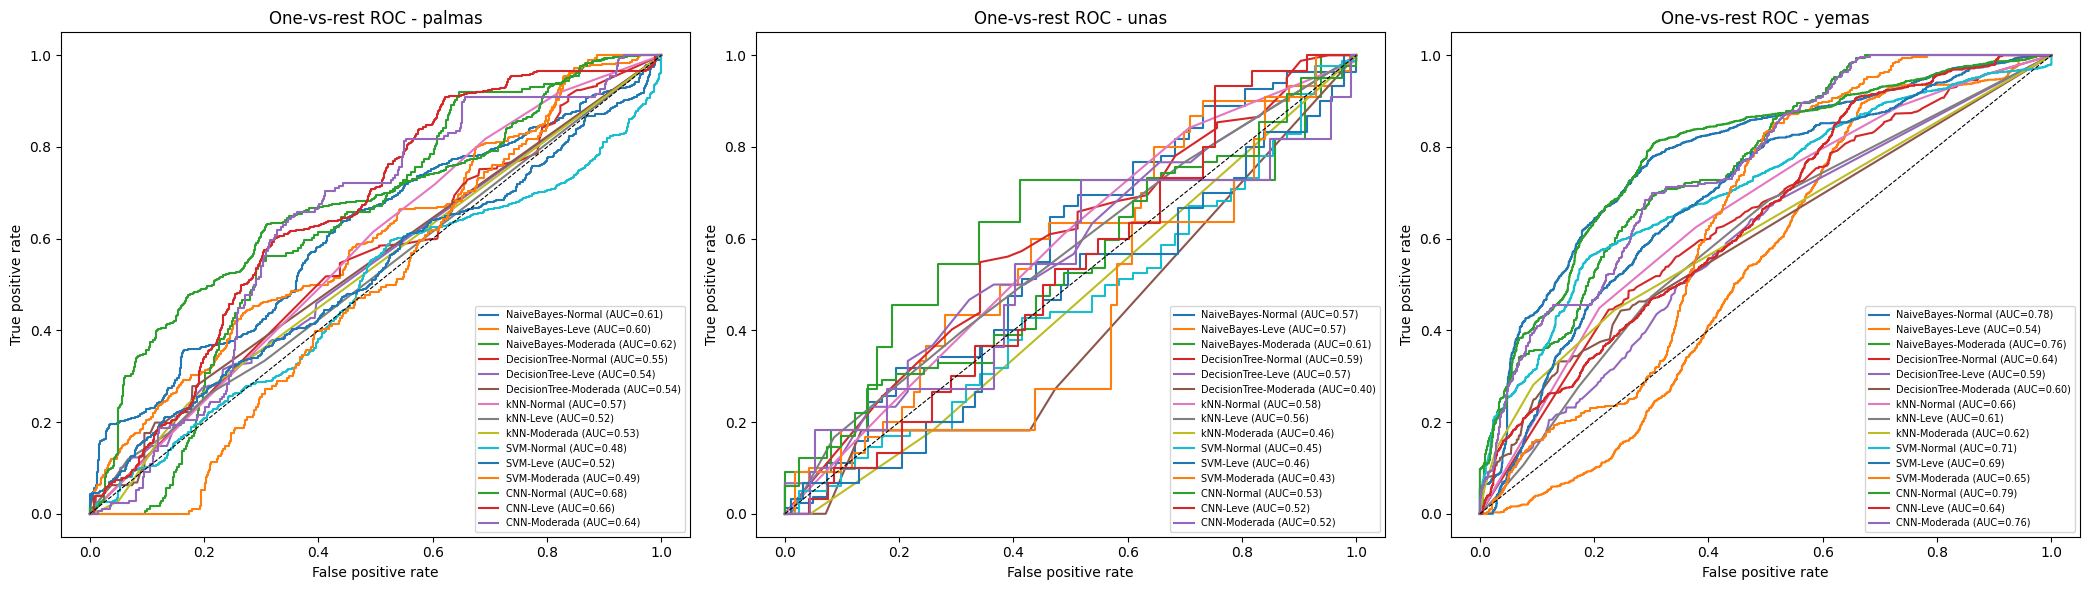

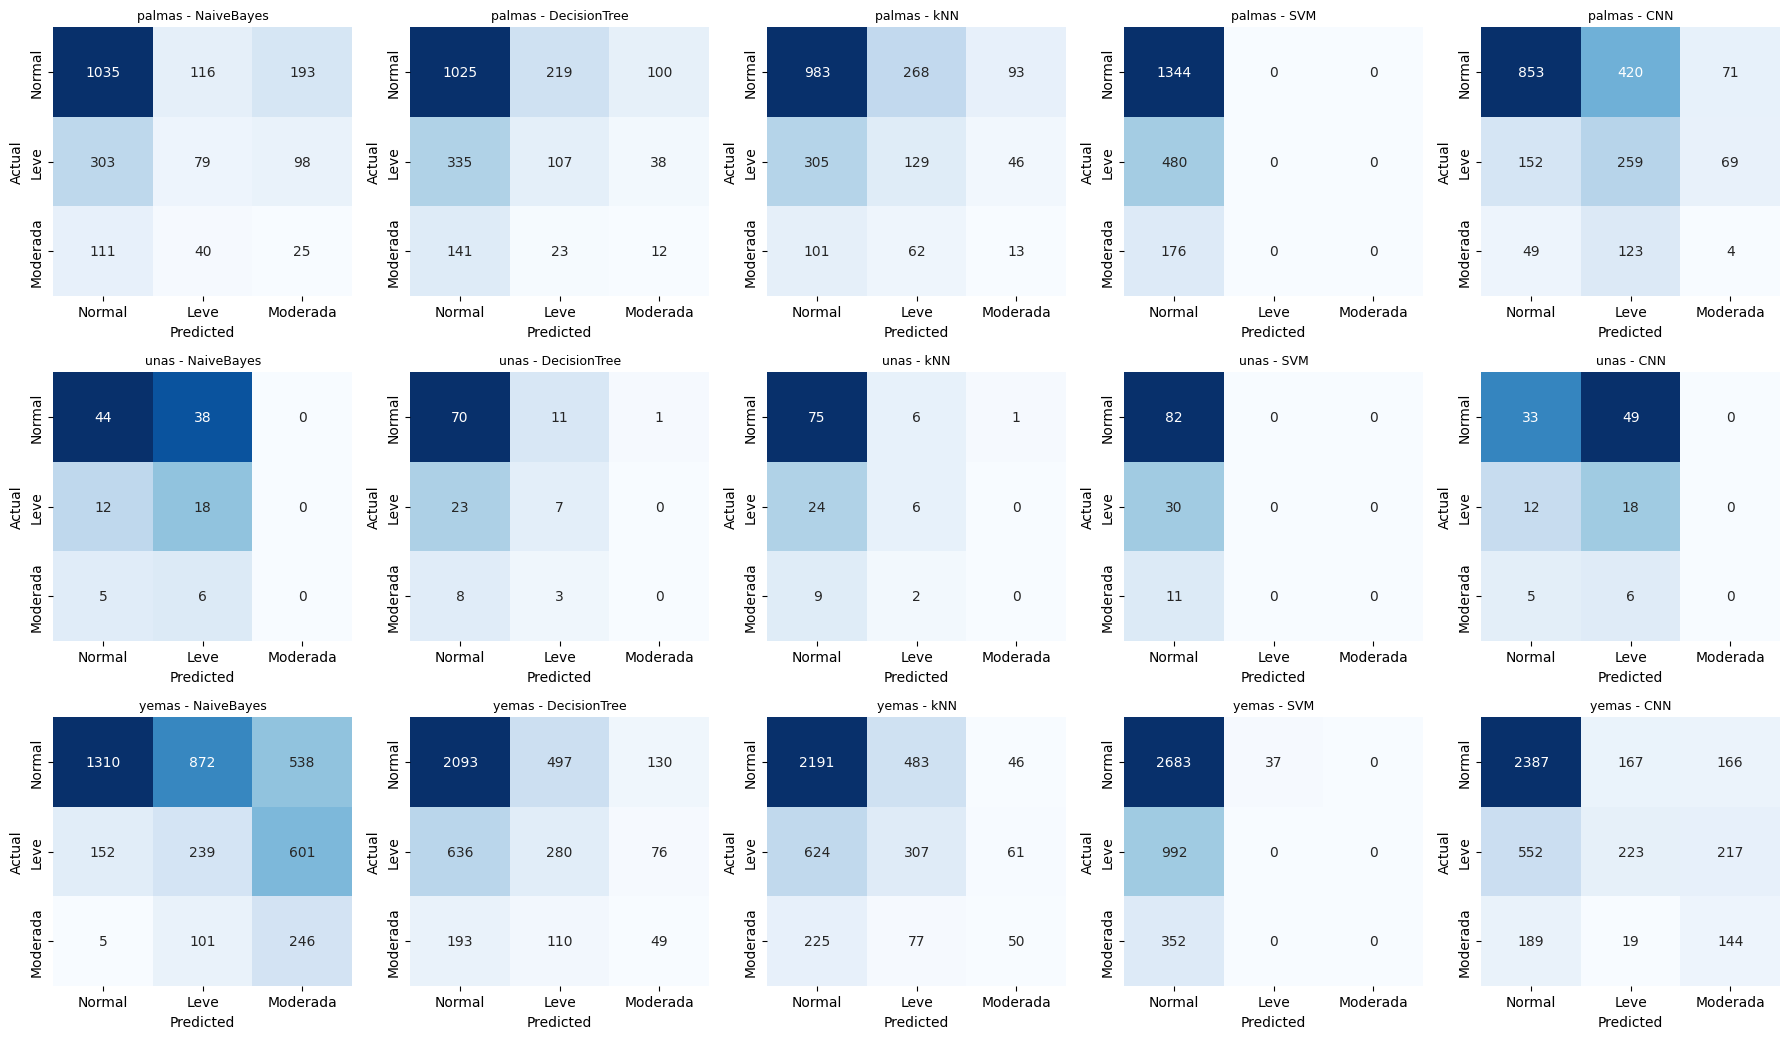

Saved summary: /kaggle/working/anemia_ckpt_3class/summary_test_metrics.csv
Saved ROC curves: /kaggle/working/anemia_ckpt_3class/roc_curves_3class.png
Saved confusion matrices: /kaggle/working/anemia_ckpt_3class/confusion_matrices_3class.png


In [52]:
# CELL 8 - Final comparison, ROC curves and confusion matrices

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix
)
from sklearn.preprocessing import label_binarize

CLASS_NAMES = ["Normal", "Leve", "Moderada"]
LABEL_IDS = [0, 1, 2]
ORDER = ["NaiveBayes", "DecisionTree", "kNN", "SVM", "CNN"]

results_dir = WORK / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Summary table
# --------------------------------------------------

rows = []

for f in sorted(results_dir.glob("*__*.json")):
    try:
        with open(f) as fp:
            r = json.load(fp)

        if "test" not in r:
            continue

        t = r["test"]
        cv = r.get("cv")
        cv_acc = np.nan

        if isinstance(cv, dict):
            acc_values = cv.get("accuracy")
            if isinstance(acc_values, (list, tuple)) and len(acc_values):
                cv_acc = float(np.mean(acc_values))

        rows.append({
            "site": r.get("site", "unknown"),
            "model": r.get("model", f.stem.split("__")[-1]),
            "accuracy": t.get("accuracy", np.nan),
            "macro_precision": t.get("precision", np.nan),
            "macro_recall": t.get("recall", np.nan),
            "macro_f1": t.get("f1", np.nan),
            "macro_ovr_auc": t.get("roc_auc", np.nan),
            "cv_accuracy": cv_acc
        })

    except (json.JSONDecodeError, OSError) as e:
        print("Could not read:", f.name, "|", e)

if not rows:
    raise ValueError(
        "No evaluation result files found. Run Cell 6 and Cell 7 first."
    )

summary = pd.DataFrame(rows)

summary = summary.sort_values(
    ["site", "macro_f1"],
    ascending=[True, False]
)

summary.to_csv(
    WORK / "summary_test_metrics.csv",
    index=False
)

print("Test-set model comparison (sorted by macro-F1):")
display(summary.round(4))


# --------------------------------------------------
# 2. One-vs-rest ROC curves
# --------------------------------------------------

fig, axes = plt.subplots(
    1, len(SITES),
    figsize=(7 * len(SITES), 6),
    squeeze=False
)

for ax, site in zip(axes.ravel(), SITES):
    plotted = False

    for model_name in ORDER:
        prob_file = results_dir / f"{site}__{model_name}_probs.npz"

        if not prob_file.exists():
            continue

        z = np.load(prob_file)
        y = z["y"].astype(int)
        probs = z["prob"]

        if probs.ndim != 2 or probs.shape[1] != 3:
            print("Unexpected probability shape:", site, model_name)
            continue

        y_bin = label_binarize(y, classes=LABEL_IDS)

        for ci, cname in enumerate(CLASS_NAMES):
            if len(np.unique(y_bin[:, ci])) < 2:
                continue

            fpr, tpr, _ = roc_curve(y_bin[:, ci], probs[:, ci])
            class_auc = auc(fpr, tpr)

            ax.plot(
                fpr, tpr,
                label=f"{model_name}-{cname} (AUC={class_auc:.2f})"
            )
            plotted = True

    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set_title(f"One-vs-rest ROC - {site}")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")

    if plotted:
        ax.legend(loc="lower right", fontsize=7)
    else:
        ax.text(0.5, 0.5, "No probability files found", ha="center")

plt.tight_layout()
plt.savefig(
    WORK / "roc_curves_3class.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# 3. Confusion matrices
# --------------------------------------------------

fig, axes = plt.subplots(
    len(SITES),
    len(ORDER),
    figsize=(3.6 * len(ORDER), 3.5 * len(SITES)),
    squeeze=False
)

for i, site in enumerate(SITES):
    for j, model_name in enumerate(ORDER):
        ax = axes[i, j]

        result_file = results_dir / f"{site}__{model_name}.json"
        prob_file = results_dir / f"{site}__{model_name}_probs.npz"

        if not result_file.exists() or not prob_file.exists():
            ax.axis("off")
            continue

        z = np.load(prob_file)
        y_true = z["y"].astype(int)
        y_pred = np.argmax(z["prob"], axis=1)

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=LABEL_IDS
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            ax=ax,
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES
        )

        ax.set_title(f"{site} - {model_name}", fontsize=9)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(
    WORK / "confusion_matrices_3class.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Saved summary:", WORK / "summary_test_metrics.csv")
print("Saved ROC curves:", WORK / "roc_curves_3class.png")
print("Saved confusion matrices:", WORK / "confusion_matrices_3class.png")

In [54]:
from sklearn.metrics import classification_report
import numpy as np
import pandas as pd

CLASS_NAMES = ["Normal", "Leve", "Moderada"]

for site in SITES:
    for model_name in ["NaiveBayes", "DecisionTree", "kNN", "SVM", "CNN"]:
        f = WORK / "results" / f"{site}__{model_name}_probs.npz"

        if not f.exists():
            continue

        z = np.load(f)
        y_true = z["y"].astype(int)
        y_pred = np.argmax(z["prob"], axis=1)

        print(f"\n{'='*55}")
        print(f"{site} | {model_name}")
        print(f"{'='*55}")

        print(classification_report(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        ))


palmas | NaiveBayes
              precision    recall  f1-score   support

      Normal     0.7143    0.7701    0.7411      1344
        Leve     0.3362    0.1646    0.2210       480
    Moderada     0.0791    0.1420    0.1016       176

    accuracy                         0.5695      2000
   macro avg     0.3765    0.3589    0.3546      2000
weighted avg     0.5676    0.5695    0.5600      2000


palmas | DecisionTree
              precision    recall  f1-score   support

      Normal     0.6829    0.7626    0.7206      1344
        Leve     0.3066    0.2229    0.2581       480
    Moderada     0.0800    0.0682    0.0736       176

    accuracy                         0.5720      2000
   macro avg     0.3565    0.3512    0.3508      2000
weighted avg     0.5395    0.5720    0.5527      2000


palmas | kNN
              precision    recall  f1-score   support

      Normal     0.7077    0.7314    0.7194      1344
        Leve     0.2810    0.2687    0.2748       480
    Moderada     

In [53]:
import shutil
from pathlib import Path

folder = Path("/kaggle/working/anemia_ckpt_3class")
zip_path = "/kaggle/working/anemia_ckpt_3class.zip"

shutil.make_archive(
    zip_path.replace(".zip", ""),
    "zip",
    root_dir=folder.parent,
    base_dir=folder.name
)

print("ZIP created:", zip_path)
print("ZIP size (MB):", round(Path(zip_path).stat().st_size / (1024 * 1024), 2))

ZIP created: /kaggle/working/anemia_ckpt_3class.zip
ZIP size (MB): 25.71
